In [4]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, CSVLogger
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [8]:
PROJECT_DIR = Path("/content/drive/MyDrive/projet covid radiographie pulmonaire")
DATA_DIR = PROJECT_DIR / "COVID-19_Radiography_Dataset"
DATASET_ROOT = PROJECT_DIR / "COVID-19_Radiography_Dataset"
if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(f"Dossier projet introuvable : {PROJECT_DIR}. Monter Drive et vérifier PROJECT_DIR.")
if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(f"Dossier images introuvable : {DATASET_ROOT}. Respecter l'arborescence Kaggle.")
OUTPUT_DIR = Path(".")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ["COVID", "Normal", "Lung_Opacity", "Viral Pneumonia"]
EXPECTED = {"train": 13545, "validation": 3387, "test": 4233}
BATCH_SIZE = 32
IMG_HEIGHT, IMG_WIDTH = 224, 224
SEED = 42
tf.keras.utils.set_random_seed(SEED)

train_df = pd.read_csv(DATA_DIR / "train (1).csv")
val_df = pd.read_csv(DATA_DIR / "validation (1).csv")
test_df = pd.read_csv(DATA_DIR / "test (1) (1).csv")

# CONFLIT — AJOUT : contrôle du split commun et des étiquettes multiclasse.
for name, frame in (("train", train_df), ("validation", val_df), ("test", test_df)):
    assert {"filepath", "target", "class"}.issubset(frame.columns), f"{name}: colonnes manquantes"
    assert len(frame) == EXPECTED[name], f"{name}: {len(frame)} au lieu de {EXPECTED[name]}"
    assert frame[["filepath", "target", "class"]].notna().all().all(), f"{name}: valeurs nulles"
    assert frame["filepath"].is_unique, f"{name}: images dupliquées"
    assert set(frame["class"].unique()) <= set(CLASSES), f"{name}: classes inconnues"
    assert set(frame["target"].astype(str).unique()) <= {"0", "1"}
    assert (frame["target"].astype(str).eq("1") == frame["class"].eq("COVID")).all(), f"{name}: target / class incohérents"
    print(f"{name}: {len(frame)} images ; classes = {frame['class'].value_counts().to_dict()}")
assert set(train_df["class"]) == set(CLASSES)
assert set(val_df["class"]) == set(CLASSES)
train_paths = set(train_df["filepath"].astype(str))
val_paths = set(val_df["filepath"].astype(str))
test_paths = set(test_df["filepath"].astype(str))
assert not (train_paths & val_paths or train_paths & test_paths or val_paths & test_paths), "Fuite entre splits"

# CONFLIT — MODIFICATION : affectations simples et séparées, comme dans E2/E3.
train_gen_df = train_df.copy()
val_gen_df = val_df.copy()
test_gen_df = test_df.copy()

# CONFLIT — AJOUT : conversion des chemins Windows relatifs vers la racine réelle.
def resolve_image_path(csv_path):
    normalized = str(csv_path).replace("\\", "/")
    marker = "COVID-19_Radiography_Dataset/"
    if marker not in normalized:
        raise ValueError(f"Chemin CSV sans dossier dataset : {csv_path}")
    relative = normalized.split(marker, 1)[1]
    parts = Path(relative).parts
    if len(parts) != 3 or parts[1] != "images" or parts[0] not in CLASSES:
        raise ValueError(f"Structure d'image inattendue : {csv_path}")
    return str(DATASET_ROOT.joinpath(*parts))

train_gen_df["filepath"] = train_gen_df["filepath"].map(resolve_image_path)
val_gen_df["filepath"] = val_gen_df["filepath"].map(resolve_image_path)
test_gen_df["filepath"] = test_gen_df["filepath"].map(resolve_image_path)

# CONFLIT — AJOUT : vérification avant le fit, y compris pour le test non exploité.
for name, frame in (("train", train_gen_df), ("validation", val_gen_df), ("test", test_gen_df)):
    missing = [p for p in frame["filepath"] if not Path(p).is_file()]
    if missing:
        raise FileNotFoundError(f"{name}: {len(missing)} fichiers absents. Exemple : {missing[0]}. Vérifier PROJECT_DIR.")
    print(f"{name}: {len(frame)} chemins existants")

# CONFLIT — MODIFICATION : variante E2 = DA seule ; aucun oversampling.
train_fit_df = train_gen_df.copy()
assert len(train_fit_df) == EXPECTED["train"]
print("Train sans OS :", train_fit_df["class"].value_counts().to_dict())

train: 13545 images ; classes = {'Normal': 6495, 'Lung_Opacity': 3895, 'COVID': 2314, 'Viral Pneumonia': 841}
validation: 3387 images ; classes = {'Normal': 1607, 'Lung_Opacity': 977, 'COVID': 579, 'Viral Pneumonia': 224}
test: 4233 images ; classes = {'Normal': 2090, 'Lung_Opacity': 1140, 'COVID': 723, 'Viral Pneumonia': 280}
train: 13545 chemins existants
validation: 3387 chemins existants
test: 4233 chemins existants
Train sans OS : {'Normal': 6495, 'Lung_Opacity': 3895, 'COVID': 2314, 'Viral Pneumonia': 841}


In [9]:
from sklearn.utils import resample
majority_n = int(train_gen_df["class"].value_counts().max())
train_parts = []
for class_name in CLASSES:
    subset = train_gen_df[train_gen_df["class"] == class_name]
    assert len(subset) > 0
    train_parts.append(resample(subset, replace=True, n_samples=majority_n, random_state=SEED))
train_fit_df = pd.concat(train_parts, ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
print("Train avant OS :", train_gen_df["class"].value_counts().to_dict())
print("Train après OS :", train_fit_df["class"].value_counts().to_dict())
assert len(train_fit_df) == 4 * majority_n


Train avant OS : {'Normal': 6495, 'Lung_Opacity': 3895, 'COVID': 2314, 'Viral Pneumonia': 841}
Train après OS : {'Lung_Opacity': 6495, 'Normal': 6495, 'Viral Pneumonia': 6495, 'COVID': 6495}


In [10]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=False
)
val_datagen = ImageDataGenerator(rescale=1./255)

# CONFLIT — MODIFICATION : 4 classes (colonne class) au lieu du target binaire.
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_fit_df, x_col="filepath", y_col="class",
    target_size=(IMG_HEIGHT, IMG_WIDTH), color_mode="grayscale",
    classes=CLASSES, class_mode="categorical", batch_size=BATCH_SIZE,
    shuffle=True, seed=SEED
)
val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_gen_df, x_col="filepath", y_col="class",
    target_size=(IMG_HEIGHT, IMG_WIDTH), color_mode="grayscale",
    classes=CLASSES, class_mode="categorical", batch_size=BATCH_SIZE,
    shuffle=False
)
assert train_generator.n == len(train_fit_df), "Train : images écartées par le générateur"
assert val_generator.n == EXPECTED["validation"], "Validation : images écartées"
assert val_generator.class_indices == {name: i for i, name in enumerate(CLASSES)}
assert val_generator.shuffle is False
print("Train batches:", len(train_generator), "Val batches:", len(val_generator))
print("Index des classes:", val_generator.class_indices)


Found 25980 validated image filenames belonging to 4 classes.
Found 3387 validated image filenames belonging to 4 classes.
Train batches: 812 Val batches: 106
Index des classes: {'COVID': 0, 'Normal': 1, 'Lung_Opacity': 2, 'Viral Pneumonia': 3}


In [11]:
def build_cnn_multiclass():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 1)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(4, activation="softmax")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

model = build_cnn_multiclass()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,168,900 (42.61 MB)

 Trainable params: 11,168,900 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
MODEL_PATH = OUTPUT_DIR / "M_CNN_from_E3_multiclass_best.keras"
HISTORY_PATH = OUTPUT_DIR / "M_CNN_from_E3_multiclass_history.csv"
callbacks = [
    EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    ModelCheckpoint(str(MODEL_PATH), monitor="val_loss", save_best_only=True),
    CSVLogger(str(HISTORY_PATH))
]
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=5,
    callbacks=callbacks
)
print("Meilleur checkpoint :", MODEL_PATH)


Epoch 1/5
812/812 ━━━━━━━━━━━━━━━━━━━━ 4684s 6s/step - accuracy: 0.6382 - loss: 0.8394 - val_accuracy: 0.7428 - val_loss: 0.6467
Epoch 2/5
812/812 ━━━━━━━━━━━━━━━━━━━━ 2909s 4s/step - accuracy: 0.7494 - loss: 0.6225 - val_accuracy: 0.7842 - val_loss: 0.5389
Epoch 3/5
812/812 ━━━━━━━━━━━━━━━━━━━━ 2935s 4s/step - accuracy: 0.7929 - loss: 0.5310 - val_accuracy: 0.8288 - val_loss: 0.4568
Epoch 4/5
812/812 ━━━━━━━━━━━━━━━━━━━━ 2936s 4s/step - accuracy: 0.8179 - loss: 0.4701 - val_accuracy: 0.8311 - val_loss: 0.4262
Epoch 5/5
812/812 ━━━━━━━━━━━━━━━━━━━━ 2919s 4s/step - accuracy: 0.8358 - loss: 0.4251 - val_accuracy: 0.8491 - val_loss: 0.3870
Meilleur checkpoint : M_CNN_from_E3_multiclass_best.keras


106/106 ━━━━━━━━━━━━━━━━━━━━ 104s 977ms/step
                 precision    recall  f1-score      support
COVID             0.846543  0.867012  0.856655   579.000000
Normal            0.865960  0.864343  0.865151  1607.000000
Lung_Opacity      0.816262  0.791198  0.803534   977.000000
Viral Pneumonia   0.872428  0.946429  0.907923   224.000000
accuracy          0.849129  0.849129  0.849129     0.849129
macro avg         0.850298  0.867245  0.858316  3387.000000
weighted avg      0.848733  0.849129  0.848754  3387.000000
Accuracy : 0.8491290227339828
F1 macro : 0.8583158872827388
Recall macro : 0.8672454254847128
Recall COVID : 0.8670120898100173
F1 COVID : 0.856655290102389


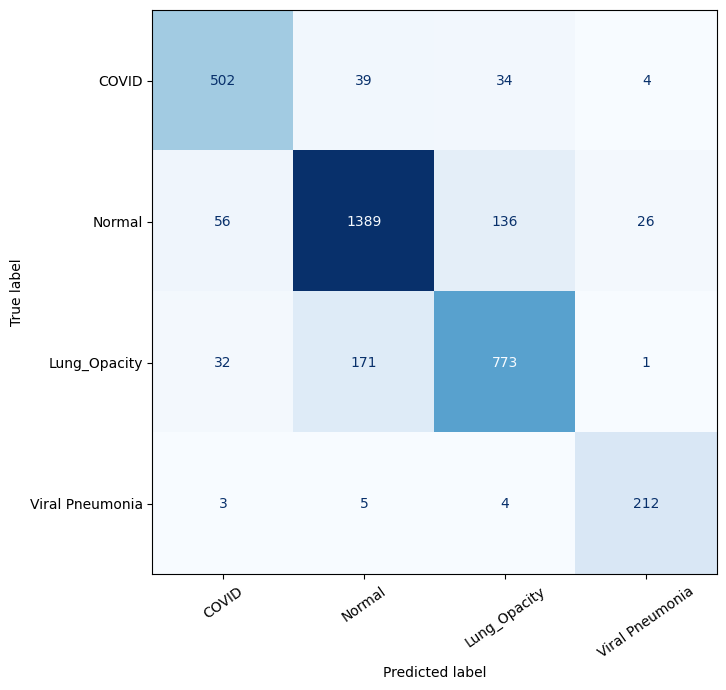

In [13]:
best_model = tf.keras.models.load_model(str(MODEL_PATH))
val_generator.reset()
proba = best_model.predict(val_generator, verbose=1)
assert len(proba) == val_generator.n == EXPECTED["validation"]
y_pred = np.argmax(proba, axis=1)
y_true = val_generator.classes
labels = list(range(len(CLASSES)))
report = classification_report(
    y_true, y_pred, labels=labels, target_names=CLASSES,
    output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv(OUTPUT_DIR / "M_CNN_from_E3_classification_report.csv")
print(report_df.to_string())
print("Accuracy :", report["accuracy"])
print("F1 macro :", report["macro avg"]["f1-score"])
print("Recall macro :", report["macro avg"]["recall"])
print("Recall COVID :", report["COVID"]["recall"])
print("F1 COVID :", report["COVID"]["f1-score"])

cm = confusion_matrix(y_true, y_pred, labels=labels)
pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(
    OUTPUT_DIR / "M_CNN_from_E3_confusion_matrix.csv"
)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES).plot(
    ax=ax, cmap="Blues", xticks_rotation=35, colorbar=False
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "M_CNN_from_E3_confusion_matrix.png", dpi=160)
plt.show()


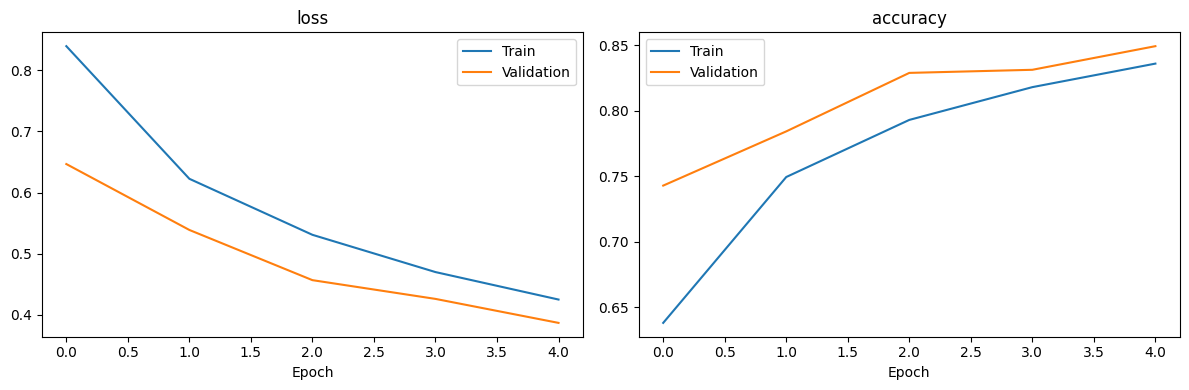

In [14]:
history_df = pd.read_csv(HISTORY_PATH)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(history_df[metric], label="Train")
    ax.plot(history_df["val_" + metric], label="Validation")
    ax.set_title(metric)
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "M_CNN_from_E3_learning_curves.png", dpi=160)
plt.show()
